In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/pima_diabetes.csv")

print("Dataset cargado correctamente")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

df.head()

Dataset cargado correctamente
Filas: 768
Columnas: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
import os

print("Carpeta actual:")
print(os.getcwd())

print("\nContenido de la carpeta actual:")
print(os.listdir())

Carpeta actual:
c:\Users\alain\.vscode\DIABETES_AI\notebooks

Contenido de la carpeta actual:
['01_auditoria_dataset.ipynb', '02_pima_eda.ipynb']


In [3]:
print("\nContenido de ../data:")
print(os.listdir("../data"))


Contenido de ../data:
['diabetes.csv', 'diabetes_ai.db', 'processed', 'raw', 'test']


In [4]:
print("\nContenido de ../data/raw:")
print(os.listdir("../data/raw"))


Contenido de ../data/raw:
['pima_diabetes.csv']


In [5]:
print("=== INFORMACIÓN GENERAL ===")
df.info()

=== INFORMACIÓN GENERAL ===
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
print("=== COLUMNAS ===")
print(df.columns.tolist())

=== COLUMNAS ===
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [7]:
print("=== ESTADÍSTICAS DESCRIPTIVAS ===")
display(df.describe().T)

=== ESTADÍSTICAS DESCRIPTIVAS ===


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [8]:
print("=== CANTIDAD DE CEROS POR VARIABLE ===")

ceros = (df == 0).sum()

print(ceros)

=== CANTIDAD DE CEROS POR VARIABLE ===
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


In [9]:
print("=== PORCENTAJE DE CEROS ===")

porcentaje_ceros = ((df == 0).sum() / len(df)) * 100

print(porcentaje_ceros.round(2))

=== PORCENTAJE DE CEROS ===
Pregnancies                 14.45
Glucose                      0.65
BloodPressure                4.56
SkinThickness               29.56
Insulin                     48.70
BMI                          1.43
DiabetesPedigreeFunction     0.00
Age                          0.00
Outcome                     65.10
dtype: float64


In [10]:
print("=== DISTRIBUCIÓN DE OUTCOME ===")

print(df["Outcome"].value_counts())

print("\n=== PORCENTAJES ===")

print(
    (df["Outcome"].value_counts(normalize=True) * 100)
    .round(2)
)

=== DISTRIBUCIÓN DE OUTCOME ===
Outcome
0    500
1    268
Name: count, dtype: int64

=== PORCENTAJES ===
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64


In [11]:
print("=== VARIABLES CON POSIBLES CEROS COMO DATOS FALTANTES ===")

variables_clinicas = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for columna in variables_clinicas:
    cantidad = (df[columna] == 0).sum()
    porcentaje = cantidad / len(df) * 100
    
    print(f"{columna}: {cantidad} ({porcentaje:.2f}%)")

=== VARIABLES CON POSIBLES CEROS COMO DATOS FALTANTES ===
Glucose: 5 (0.65%)
BloodPressure: 35 (4.56%)
SkinThickness: 227 (29.56%)
Insulin: 374 (48.70%)
BMI: 11 (1.43%)


In [12]:
print("=== CEROS POR VARIABLE Y OUTCOME ===")

for columna in variables_clinicas:
    print(f"\n{columna}")
    print(
        pd.crosstab(
            df[columna] == 0,
            df["Outcome"],
            margins=True
        )
    )

=== CEROS POR VARIABLE Y OUTCOME ===

Glucose
Outcome    0    1  All
Glucose               
False    497  266  763
True       3    2    5
All      500  268  768

BloodPressure
Outcome          0    1  All
BloodPressure               
False          481  252  733
True            19   16   35
All            500  268  768

SkinThickness
Outcome          0    1  All
SkinThickness               
False          361  180  541
True           139   88  227
All            500  268  768

Insulin
Outcome    0    1  All
Insulin               
False    264  130  394
True     236  138  374
All      500  268  768

BMI
Outcome    0    1  All
BMI                   
False    491  266  757
True       9    2   11
All      500  268  768


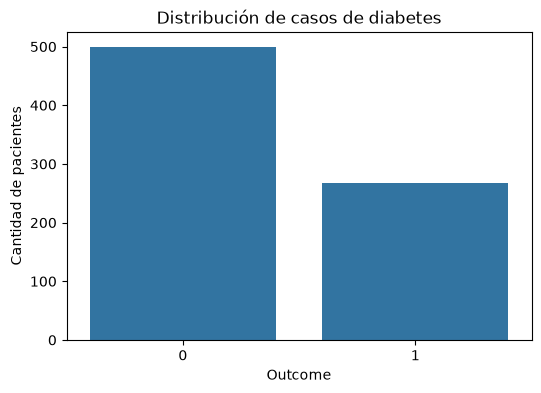

In [13]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Outcome")

plt.title("Distribución de casos de diabetes")
plt.xlabel("Outcome")
plt.ylabel("Cantidad de pacientes")

plt.show()

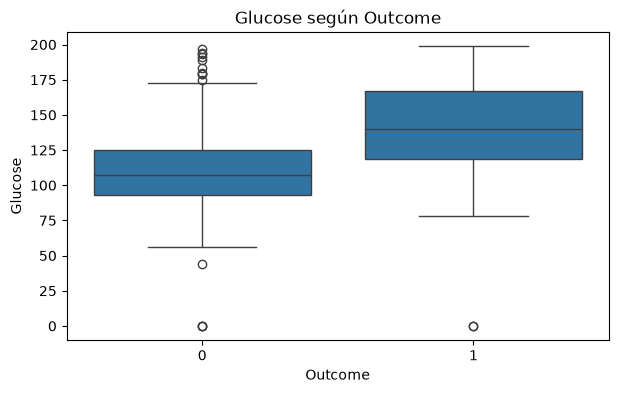

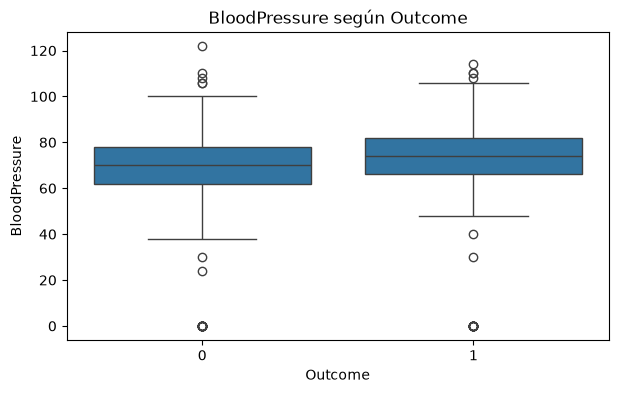

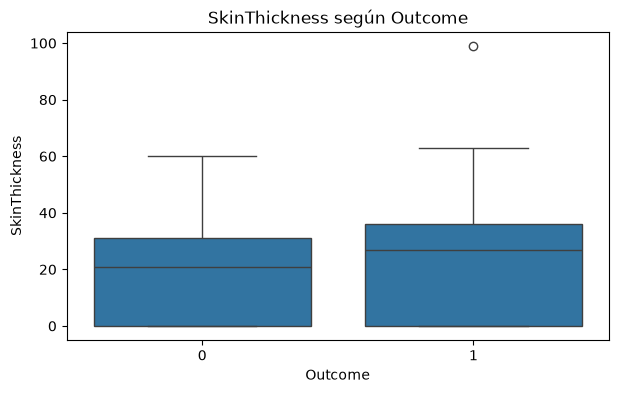

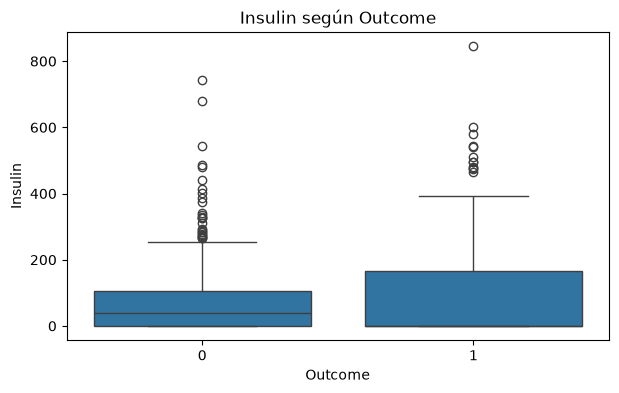

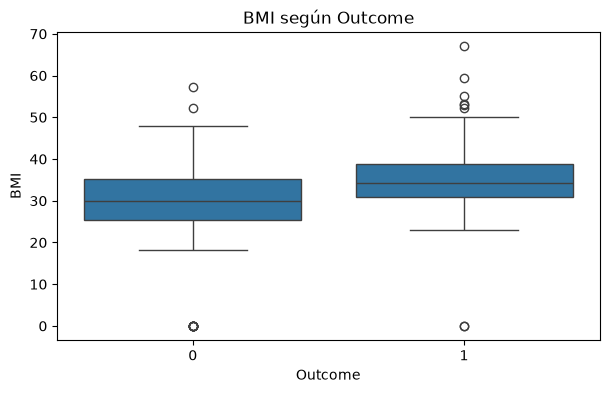

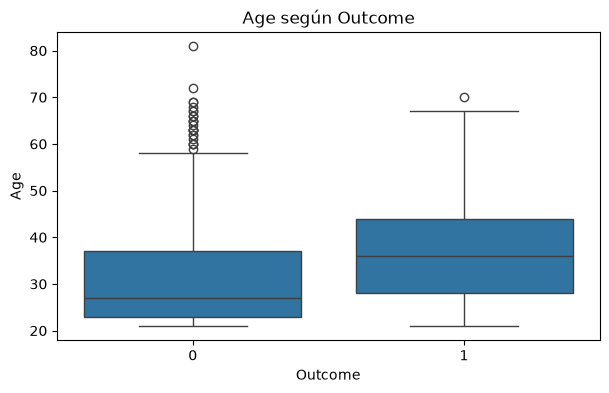

In [14]:
variables = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "Age"
]

for variable in variables:
    plt.figure(figsize=(7, 4))
    
    sns.boxplot(
        data=df,
        x="Outcome",
        y=variable
    )
    
    plt.title(f"{variable} según Outcome")
    plt.xlabel("Outcome")
    plt.ylabel(variable)
    
    plt.show()

In [15]:
print("=== MEDIAS POR OUTCOME ===")

display(
    df.groupby("Outcome")[variables]
      .mean()
      .T
)

=== MEDIAS POR OUTCOME ===


Outcome,0,1
Glucose,109.9800,141.257463
BloodPressure,68.1840,70.824627
SkinThickness,19.6640,22.164179
Insulin,68.7920,100.335821
BMI,30.3042,35.142537
Age,31.1900,37.067164


In [16]:
print("=== MEDIANAS POR OUTCOME ===")

display(
    df.groupby("Outcome")[variables]
      .median()
      .T
)

=== MEDIANAS POR OUTCOME ===


Outcome,0,1
Glucose,107.00,140.00
BloodPressure,70.00,74.00
SkinThickness,21.00,27.00
Insulin,39.00,0.00
BMI,30.05,34.25
Age,27.00,36.00


In [17]:
print("=== PREPARACIÓN DEL DATASET ===")

df_clean = df.copy()

variables_cero_faltante = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df_clean[variables_cero_faltante] = (
    df_clean[variables_cero_faltante]
    .replace(0, np.nan)
)

print("Dataset preparado.")
print(f"Filas: {df_clean.shape[0]}")
print(f"Columnas: {df_clean.shape[1]}")

=== PREPARACIÓN DEL DATASET ===
Dataset preparado.
Filas: 768
Columnas: 9


In [18]:
print("=== VALORES FALTANTES DESPUÉS DE CONVERTIR CEROS ===")

missing = df_clean.isnull().sum()

print(missing)

=== VALORES FALTANTES DESPUÉS DE CONVERTIR CEROS ===
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [19]:
print("=== PORCENTAJE DE DATOS FALTANTES ===")

missing_pct = (
    df_clean.isnull().sum() / len(df_clean) * 100
)

print(missing_pct.round(2))

=== PORCENTAJE DE DATOS FALTANTES ===
Pregnancies                  0.00
Glucose                      0.65
BloodPressure                4.56
SkinThickness               29.56
Insulin                     48.70
BMI                          1.43
DiabetesPedigreeFunction     0.00
Age                          0.00
Outcome                      0.00
dtype: float64


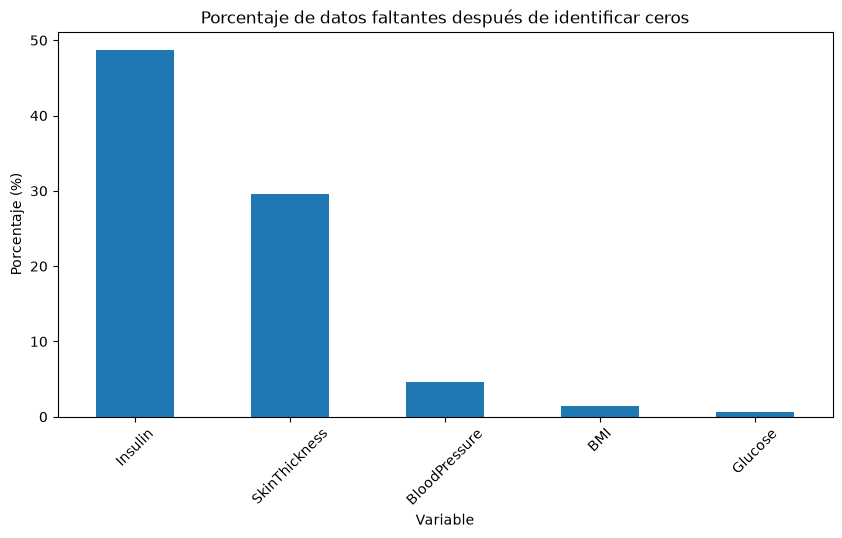

In [20]:
plt.figure(figsize=(10, 5))

missing_pct[missing_pct > 0].sort_values(ascending=False).plot(
    kind="bar"
)

plt.title("Porcentaje de datos faltantes después de identificar ceros")
plt.xlabel("Variable")
plt.ylabel("Porcentaje (%)")
plt.xticks(rotation=45)

plt.show()

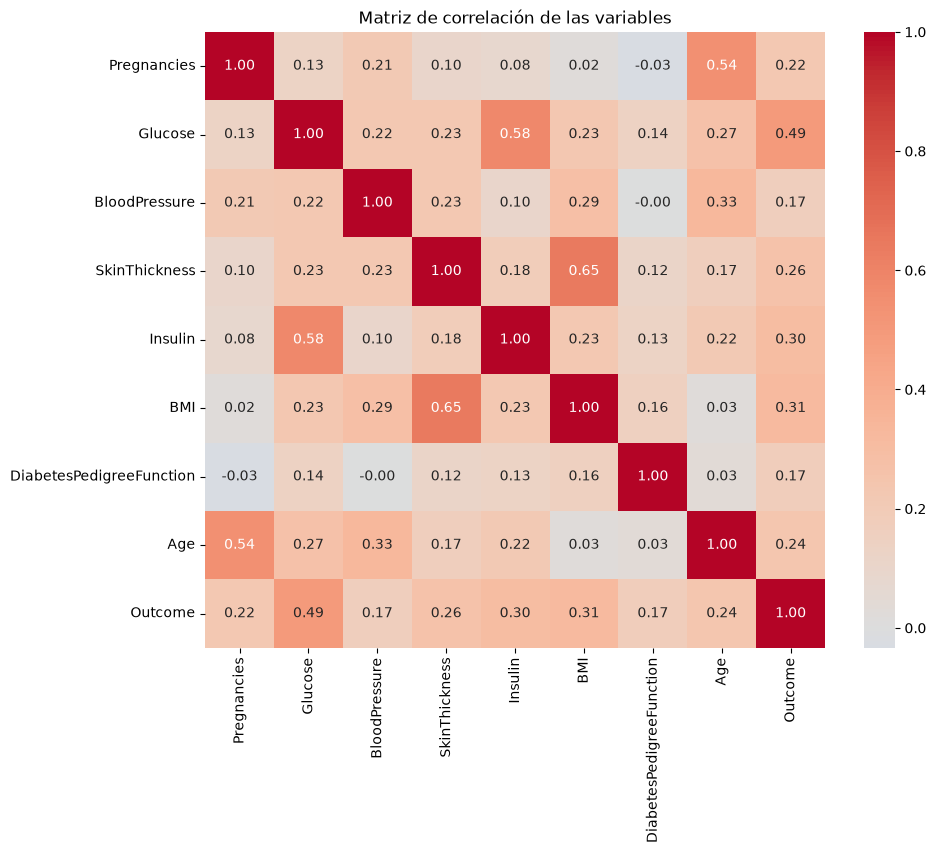

In [21]:
plt.figure(figsize=(10, 8))

correlacion = df_clean.corr(numeric_only=True)

sns.heatmap(
    correlacion,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación de las variables")
plt.show()

In [22]:
print("=== CORRELACIÓN CON OUTCOME ===")

correlacion_outcome = (
    df_clean.corr(numeric_only=True)["Outcome"]
    .sort_values(ascending=False)
)

print(correlacion_outcome.round(3))

=== CORRELACIÓN CON OUTCOME ===
Outcome                     1.000
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


In [23]:
print("=== SEPARACIÓN DE VARIABLES ===")

X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

print("\nVariables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)

=== SEPARACIÓN DE VARIABLES ===
Dimensiones de X: (768, 8)
Dimensiones de y: (768,)

Variables predictoras:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Variable objetivo:
Outcome


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=== DIVISIÓN TRAIN / TEST ===")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

=== DIVISIÓN TRAIN / TEST ===
X_train: (614, 8)
X_test: (154, 8)
y_train: (614,)
y_test: (154,)


In [25]:
print("=== DISTRIBUCIÓN DE CLASES ===")

print("Train:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest:")
print(y_test.value_counts(normalize=True).round(3))

=== DISTRIBUCIÓN DE CLASES ===
Train:
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64

Test:
Outcome
0    0.649
1    0.351
Name: proportion, dtype: float64


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Pipeline de preprocesamiento creado correctamente.")

Pipeline de preprocesamiento creado correctamente.


In [27]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("=== DATOS PROCESADOS ===")
print("X_train procesado:", X_train_processed.shape)
print("X_test procesado:", X_test_processed.shape)

=== DATOS PROCESADOS ===
X_train procesado: (614, 8)
X_test procesado: (154, 8)


In [28]:
import numpy as np

print("Valores NaN en X_train procesado:",
      np.isnan(X_train_processed).sum())

print("Valores NaN en X_test procesado:",
      np.isnan(X_test_processed).sum())

Valores NaN en X_train procesado: 0
Valores NaN en X_test procesado: 0


In [29]:
print("=== MEDIA Y DESVIACIÓN DEL TRAIN PROCESADO ===")

print("Media aproximada:")
print(np.mean(X_train_processed, axis=0).round(3))

print("\nDesviación estándar aproximada:")
print(np.std(X_train_processed, axis=0).round(3))

=== MEDIA Y DESVIACIÓN DEL TRAIN PROCESADO ===
Media aproximada:
[-0. -0.  0. -0. -0.  0. -0. -0.]

Desviación estándar aproximada:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [30]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Modelo de Regresión Logística creado correctamente.")

Modelo de Regresión Logística creado correctamente.


In [31]:
print("=== ENTRENAMIENTO ===")

logistic_model.fit(X_train, y_train)

print("Regresión Logística entrenada correctamente.")

=== ENTRENAMIENTO ===
Regresión Logística entrenada correctamente.


In [32]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predicciones realizadas correctamente.")

print("\nPrimeras 10 predicciones:")
print(y_pred[:10])

print("\nPrimeras 10 probabilidades:")
print(y_prob[:10])

Predicciones realizadas correctamente.

Primeras 10 predicciones:
[1 0 0 0 0 0 0 1 0 1]

Primeras 10 probabilidades:
[0.60969998 0.11829145 0.29342565 0.25080052 0.03352696 0.16847753
 0.48806448 0.92366487 0.0814217  0.83859286]


In [33]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("=== REGRESIÓN LOGÍSTICA ===")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

=== REGRESIÓN LOGÍSTICA ===
Accuracy : 0.7078
Precision: 0.6000
Recall   : 0.5000
F1-score : 0.5455
ROC-AUC  : 0.8130


=== MATRIZ DE CONFUSIÓN ===
[[82 18]
 [27 27]]


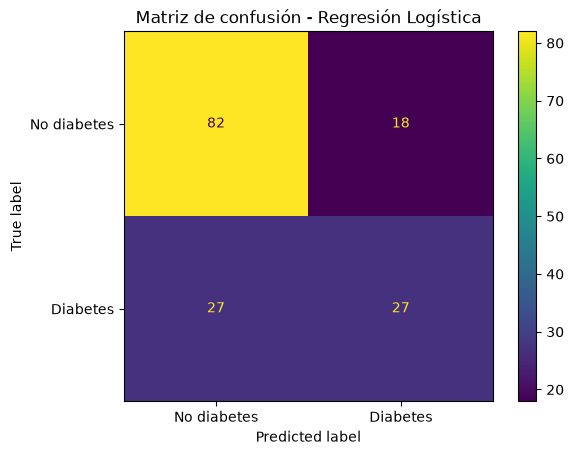

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("=== MATRIZ DE CONFUSIÓN ===")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Matriz de confusión - Regresión Logística")
plt.show()

In [35]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

print("Modelo SVM creado correctamente.")

Modelo SVM creado correctamente.


In [36]:
print("=== ENTRENAMIENTO SVM ===")

svm_model.fit(X_train, y_train)

print("SVM entrenado correctamente.")

=== ENTRENAMIENTO SVM ===
SVM entrenado correctamente.


c:\Users\alain\.vscode\DIABETES_AI\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [37]:
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

print("Predicciones SVM realizadas correctamente.")

Predicciones SVM realizadas correctamente.


In [38]:
accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_prob_svm)

print("=== SVM ===")
print(f"Accuracy : {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall   : {recall_svm:.4f}")
print(f"F1-score : {f1_svm:.4f}")
print(f"ROC-AUC  : {roc_auc_svm:.4f}")

=== SVM ===
Accuracy : 0.7403
Precision: 0.6522
Recall   : 0.5556
F1-score : 0.6000
ROC-AUC  : 0.7964


=== MATRIZ DE CONFUSIÓN - SVM ===
[[84 16]
 [24 30]]


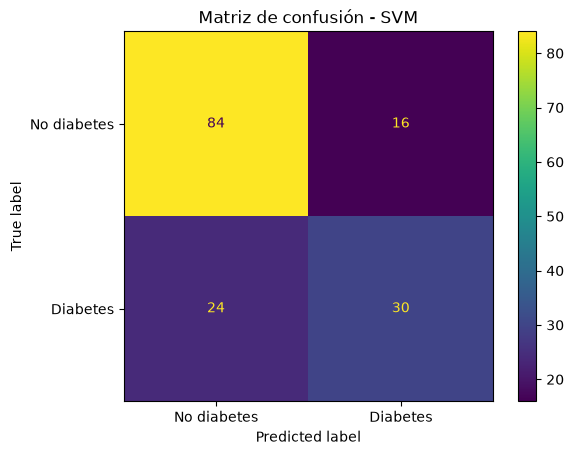

In [39]:
cm_svm = confusion_matrix(y_test, y_pred_svm)

print("=== MATRIZ DE CONFUSIÓN - SVM ===")
print(cm_svm)

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Matriz de confusión - SVM")
plt.show()

In [40]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=5
    ))
])

print("Modelo KNN creado correctamente.")

Modelo KNN creado correctamente.


In [41]:
print("=== ENTRENAMIENTO KNN ===")

knn_model.fit(X_train, y_train)

print("KNN entrenado correctamente.")

=== ENTRENAMIENTO KNN ===
KNN entrenado correctamente.


In [42]:
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

print("Predicciones KNN realizadas correctamente.")

Predicciones KNN realizadas correctamente.


In [43]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("=== KNN ===")
print(f"Accuracy : {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall   : {recall_knn:.4f}")
print(f"F1-score : {f1_knn:.4f}")
print(f"ROC-AUC  : {roc_auc_knn:.4f}")

=== KNN ===
Accuracy : 0.7532
Precision: 0.6600
Recall   : 0.6111
F1-score : 0.6346
ROC-AUC  : 0.7899


=== MATRIZ DE CONFUSIÓN - KNN ===
[[83 17]
 [21 33]]


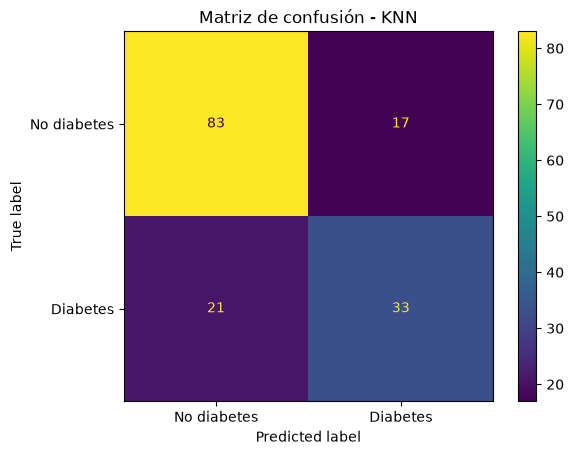

In [44]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

print("=== MATRIZ DE CONFUSIÓN - KNN ===")
print(cm_knn)

ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Matriz de confusión - KNN")
plt.show()

In [45]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Modelo Random Forest creado correctamente.")

Modelo Random Forest creado correctamente.


In [46]:
print("=== ENTRENAMIENTO RANDOM FOREST ===")

rf_model.fit(X_train, y_train)

print("Random Forest entrenado correctamente.")

=== ENTRENAMIENTO RANDOM FOREST ===
Random Forest entrenado correctamente.


In [47]:
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Predicciones Random Forest realizadas correctamente.")

Predicciones Random Forest realizadas correctamente.


In [48]:
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("=== RANDOM FOREST ===")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-score : {f1_rf:.4f}")
print(f"ROC-AUC  : {roc_auc_rf:.4f}")

=== RANDOM FOREST ===
Accuracy : 0.7662
Precision: 0.6957
Recall   : 0.5926
F1-score : 0.6400
ROC-AUC  : 0.8210


=== MATRIZ DE CONFUSIÓN - RANDOM FOREST ===
[[86 14]
 [22 32]]


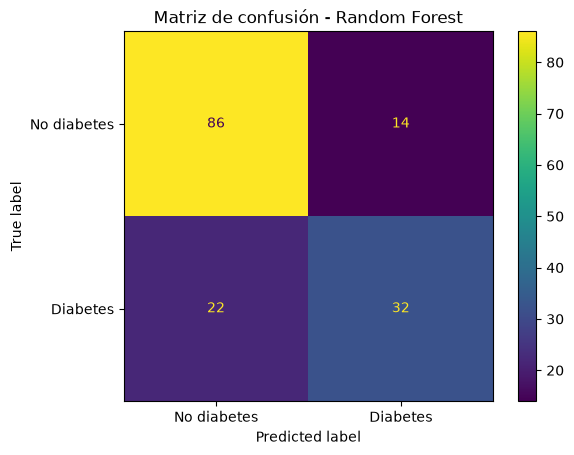

In [49]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print("=== MATRIZ DE CONFUSIÓN - RANDOM FOREST ===")
print(cm_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Matriz de confusión - Random Forest")
plt.show()

In [50]:
from sklearn.neural_network import MLPClassifier

mlp_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=1000,
        random_state=42,
        early_stopping=True
    ))
])

print("Modelo MLP creado correctamente.")

Modelo MLP creado correctamente.


In [51]:
print("=== ENTRENAMIENTO MLP ===")

mlp_model.fit(X_train, y_train)

print("MLP entrenado correctamente.")

=== ENTRENAMIENTO MLP ===
MLP entrenado correctamente.


In [52]:
y_pred_mlp = mlp_model.predict(X_test)
y_prob_mlp = mlp_model.predict_proba(X_test)[:, 1]

print("Predicciones MLP realizadas correctamente.")

Predicciones MLP realizadas correctamente.


In [53]:
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)
precision_mlp = precision_score(y_test, y_pred_mlp)
recall_mlp = recall_score(y_test, y_pred_mlp)
f1_mlp = f1_score(y_test, y_pred_mlp)
roc_auc_mlp = roc_auc_score(y_test, y_prob_mlp)

print("=== MLP ===")
print(f"Accuracy : {accuracy_mlp:.4f}")
print(f"Precision: {precision_mlp:.4f}")
print(f"Recall   : {recall_mlp:.4f}")
print(f"F1-score : {f1_mlp:.4f}")
print(f"ROC-AUC  : {roc_auc_mlp:.4f}")

=== MLP ===
Accuracy : 0.7208
Precision: 0.6170
Recall   : 0.5370
F1-score : 0.5743
ROC-AUC  : 0.8176


=== MATRIZ DE CONFUSIÓN - MLP ===
[[82 18]
 [25 29]]


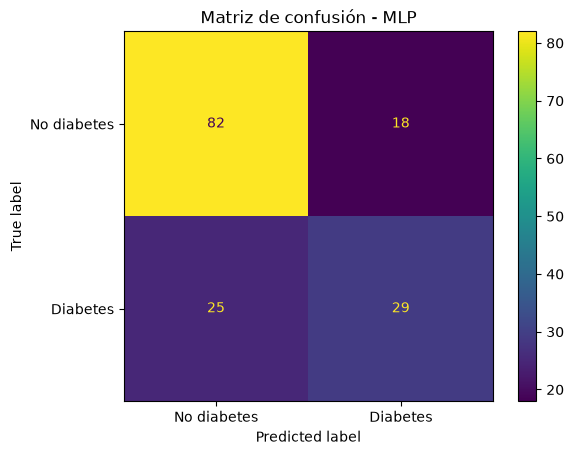

In [54]:
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

print("=== MATRIZ DE CONFUSIÓN - MLP ===")
print(cm_mlp)

ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Matriz de confusión - MLP")
plt.show()

In [55]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Validación cruzada configurada correctamente.")

Validación cruzada configurada correctamente.


In [56]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [57]:
models = {
    "Regresión Logística": logistic_model,
    "SVM": svm_model,
    "KNN": knn_model,
    "Random Forest": rf_model,
    "MLP": mlp_model
}

In [58]:
cv_results = []

for nombre, modelo in models.items():
    
    resultados = cross_validate(
        modelo,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    
    cv_results.append({
        "Modelo": nombre,
        "Accuracy": resultados["test_accuracy"].mean(),
        "Precision": resultados["test_precision"].mean(),
        "Recall": resultados["test_recall"].mean(),
        "F1": resultados["test_f1"].mean(),
        "ROC-AUC": resultados["test_roc_auc"].mean()
    })

cv_df = pd.DataFrame(cv_results)

print("=== RESULTADOS VALIDACIÓN CRUZADA ===")
display(cv_df.round(4))

=== RESULTADOS VALIDACIÓN CRUZADA ===


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Regresión Logística,0.7721,0.7261,0.5711,0.6358,0.8366
1,SVM,0.7539,0.6896,0.5447,0.6073,0.8210
2,KNN,0.7213,0.6108,0.5669,0.5871,0.7804
3,Random Forest,0.7577,0.6769,0.5894,0.6294,0.8210
4,MLP,0.7461,0.6998,0.5080,0.5754,0.8342


In [59]:
cv_results_detailed = []

for nombre, modelo in models.items():

    resultados = cross_validate(
        modelo,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results_detailed.append({
        "Modelo": nombre,

        "Accuracy_mean": resultados["test_accuracy"].mean(),
        "Accuracy_std": resultados["test_accuracy"].std(),

        "Precision_mean": resultados["test_precision"].mean(),
        "Precision_std": resultados["test_precision"].std(),

        "Recall_mean": resultados["test_recall"].mean(),
        "Recall_std": resultados["test_recall"].std(),

        "F1_mean": resultados["test_f1"].mean(),
        "F1_std": resultados["test_f1"].std(),

        "ROC_AUC_mean": resultados["test_roc_auc"].mean(),
        "ROC_AUC_std": resultados["test_roc_auc"].std()
    })

cv_detailed_df = pd.DataFrame(cv_results_detailed)

display(cv_detailed_df.round(4))

,Modelo,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,ROC_AUC_mean,ROC_AUC_std
0,Regresión Logística,0.7721,0.0166,0.7261,0.0617,0.5711,0.0474,0.6358,0.0210,0.8366,0.0203
1,SVM,0.7539,0.0212,0.6896,0.0551,0.5447,0.0259,0.6073,0.0262,0.8210,0.0120
2,KNN,0.7213,0.0330,0.6108,0.0576,0.5669,0.0410,0.5871,0.0428,0.7804,0.0220
3,Random Forest,0.7577,0.0227,0.6769,0.0451,0.5894,0.0323,0.6294,0.0325,0.8210,0.0174
4,MLP,0.7461,0.0182,0.6998,0.0701,0.5080,0.1145,0.5754,0.0672,0.8342,0.0301


In [60]:
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

grid_lr = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid_lr,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

print("GridSearch configurado.")

GridSearch configurado.


In [61]:
print("=== OPTIMIZANDO REGRESIÓN LOGÍSTICA ===")

grid_lr.fit(X, y)

print("Optimización finalizada.")

=== OPTIMIZANDO REGRESIÓN LOGÍSTICA ===
Optimización finalizada.


In [62]:
print("=== MEJORES PARÁMETROS ===")
print(grid_lr.best_params_)

print("\n=== MEJOR ROC-AUC PROMEDIO ===")
print(round(grid_lr.best_score_, 4))

=== MEJORES PARÁMETROS ===
{'model__C': 0.1, 'model__solver': 'liblinear'}

=== MEJOR ROC-AUC PROMEDIO ===
0.8371


In [63]:
best_lr = grid_lr.best_estimator_

print("Mejor modelo de Regresión Logística obtenido.")

Mejor modelo de Regresión Logística obtenido.


In [64]:
y_pred_lr_opt = best_lr.predict(X_test)
y_prob_lr_opt = best_lr.predict_proba(X_test)[:, 1]

print("=== REGRESIÓN LOGÍSTICA OPTIMIZADA ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred_lr_opt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr_opt):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_lr_opt):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_lr_opt):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_lr_opt):.4f}")

=== REGRESIÓN LOGÍSTICA OPTIMIZADA ===
Accuracy : 0.6883
Precision: 0.5652
Recall   : 0.4815
F1-score : 0.5200
ROC-AUC  : 0.8163


=== MATRIZ DE CONFUSIÓN ===
[[80 20]
 [28 26]]


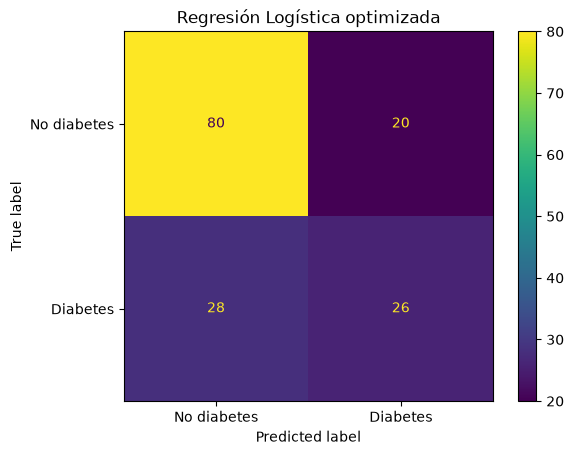

In [65]:
cm_lr_opt = confusion_matrix(y_test, y_pred_lr_opt)

print("=== MATRIZ DE CONFUSIÓN ===")
print(cm_lr_opt)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr_opt,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Regresión Logística optimizada")
plt.show()

In [66]:
param_grid_lr = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

grid_lr_corrected = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid_lr,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

In [67]:
print("=== OPTIMIZACIÓN CORREGIDA ===")

grid_lr_corrected.fit(X_train, y_train)

print("Optimización finalizada.")

=== OPTIMIZACIÓN CORREGIDA ===
Optimización finalizada.


In [68]:
print("=== OPTIMIZACIÓN CORREGIDA ===")

grid_lr_corrected.fit(X_train, y_train)

print("Optimización finalizada.")

=== OPTIMIZACIÓN CORREGIDA ===
Optimización finalizada.


In [69]:
best_lr_corrected = grid_lr_corrected.best_estimator_

y_pred_lr_final = best_lr_corrected.predict(X_test)
y_prob_lr_final = best_lr_corrected.predict_proba(X_test)[:, 1]

print("=== REGRESIÓN LOGÍSTICA — TEST FINAL ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred_lr_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr_final):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_lr_final):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_lr_final):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_lr_final):.4f}")

=== REGRESIÓN LOGÍSTICA — TEST FINAL ===
Accuracy : 0.6883
Precision: 0.5652
Recall   : 0.4815
F1-score : 0.5200
ROC-AUC  : 0.8104


=== MATRIZ DE CONFUSIÓN ===
[[80 20]
 [28 26]]


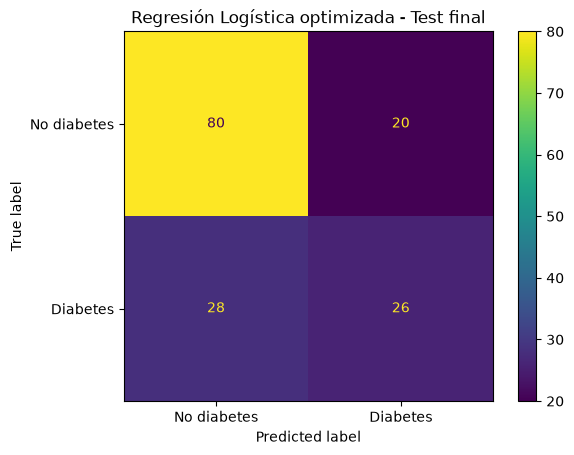

In [70]:
cm_lr_final = confusion_matrix(y_test, y_pred_lr_final)

print("=== MATRIZ DE CONFUSIÓN ===")
print(cm_lr_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm_lr_final,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Regresión Logística optimizada - Test final")
plt.show()

In [71]:
param_grid_svm = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.01, 0.1, 1],
    "model__kernel": ["rbf", "linear"]
}

grid_svm = GridSearchCV(
    estimator=svm_model,
    param_grid=param_grid_svm,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

print("GridSearch de SVM configurado.")

GridSearch de SVM configurado.


In [72]:
print("=== OPTIMIZANDO SVM ===")

grid_svm.fit(X_train, y_train)

print("Optimización de SVM finalizada.")

=== OPTIMIZANDO SVM ===
Optimización de SVM finalizada.


c:\Users\alain\.vscode\DIABETES_AI\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [73]:
print("=== MEJORES PARÁMETROS SVM ===")
print(grid_svm.best_params_)

print("\n=== MEJOR ROC-AUC EN VALIDACIÓN ===")
print(round(grid_svm.best_score_, 4))

=== MEJORES PARÁMETROS SVM ===
{'model__C': 1, 'model__gamma': 0.01, 'model__kernel': 'rbf'}

=== MEJOR ROC-AUC EN VALIDACIÓN ===
0.8463


In [74]:
best_svm = grid_svm.best_estimator_

y_pred_svm_final = best_svm.predict(X_test)
y_prob_svm_final = best_svm.predict_proba(X_test)[:, 1]

print("=== SVM OPTIMIZADO — TEST FINAL ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred_svm_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm_final):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_svm_final):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_svm_final):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_svm_final):.4f}")

=== SVM OPTIMIZADO — TEST FINAL ===
Accuracy : 0.7078
Precision: 0.6098
Recall   : 0.4630
F1-score : 0.5263
ROC-AUC  : 0.8052


=== MATRIZ DE CONFUSIÓN SVM ===
[[84 16]
 [29 25]]


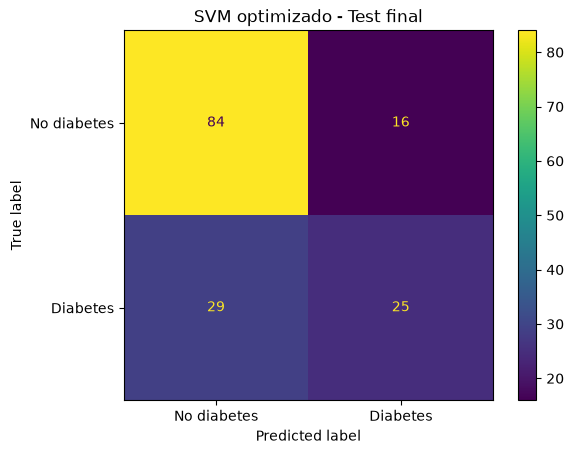

In [75]:
cm_svm_final = confusion_matrix(y_test, y_pred_svm_final)

print("=== MATRIZ DE CONFUSIÓN SVM ===")
print(cm_svm_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm_final,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("SVM optimizado - Test final")
plt.show()

In [76]:
param_grid_rf = {
    "model__n_estimators": [100, 300, 500],
    "model__max_depth": [None, 5, 10, 15],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

grid_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

print("GridSearch de Random Forest configurado.")

GridSearch de Random Forest configurado.


In [77]:
print("=== OPTIMIZANDO RANDOM FOREST ===")

grid_rf.fit(X_train, y_train)

print("Optimización de Random Forest finalizada.")

=== OPTIMIZANDO RANDOM FOREST ===
Optimización de Random Forest finalizada.


In [78]:
print("=== MEJORES PARÁMETROS RANDOM FOREST ===")
print(grid_rf.best_params_)

print("\n=== MEJOR ROC-AUC EN VALIDACIÓN ===")
print(round(grid_rf.best_score_, 4))

=== MEJORES PARÁMETROS RANDOM FOREST ===
{'model__max_depth': 5, 'model__max_features': 'log2', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

=== MEJOR ROC-AUC EN VALIDACIÓN ===
0.8408


In [79]:
best_rf = grid_rf.best_estimator_

print("Mejor Random Forest obtenido correctamente.")

Mejor Random Forest obtenido correctamente.


In [80]:
y_pred_rf_final = best_rf.predict(X_test)
y_prob_rf_final = best_rf.predict_proba(X_test)[:, 1]

print("=== RANDOM FOREST OPTIMIZADO — TEST FINAL ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred_rf_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_final):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_rf_final):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_rf_final):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_rf_final):.4f}")

=== RANDOM FOREST OPTIMIZADO — TEST FINAL ===
Accuracy : 0.7273
Precision: 0.6429
Recall   : 0.5000
F1-score : 0.5625
ROC-AUC  : 0.8043


=== MATRIZ DE CONFUSIÓN RANDOM FOREST ===
[[85 15]
 [27 27]]


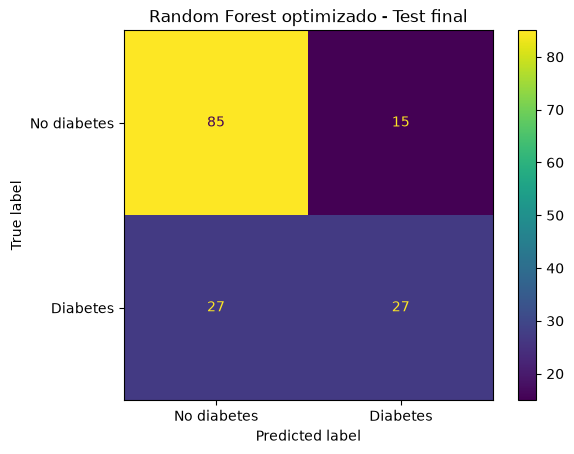

In [81]:
cm_rf_final = confusion_matrix(y_test, y_pred_rf_final)

print("=== MATRIZ DE CONFUSIÓN RANDOM FOREST ===")
print(cm_rf_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_final,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("Random Forest optimizado - Test final")
plt.show()

In [82]:
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

grid_knn = GridSearchCV(
    estimator=knn_model,
    param_grid=param_grid_knn,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

print("GridSearch de KNN configurado.")

GridSearch de KNN configurado.


In [83]:
print("=== OPTIMIZANDO KNN ===")

grid_knn.fit(X_train, y_train)

print("Optimización de KNN finalizada.")

=== OPTIMIZANDO KNN ===
Optimización de KNN finalizada.


In [84]:
print("=== MEJORES PARÁMETROS KNN ===")
print(grid_knn.best_params_)

print("\n=== MEJOR ROC-AUC EN VALIDACIÓN ===")
print(round(grid_knn.best_score_, 4))

=== MEJORES PARÁMETROS KNN ===
{'model__n_neighbors': 21, 'model__p': 2, 'model__weights': 'distance'}

=== MEJOR ROC-AUC EN VALIDACIÓN ===
0.8337


In [85]:
best_knn = grid_knn.best_estimator_

print("Mejor KNN obtenido correctamente.")

Mejor KNN obtenido correctamente.


In [86]:
y_pred_knn_final = best_knn.predict(X_test)
y_prob_knn_final = best_knn.predict_proba(X_test)[:, 1]

print("=== KNN OPTIMIZADO — TEST FINAL ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred_knn_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_knn_final):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_knn_final):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_knn_final):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_knn_final):.4f}")

=== KNN OPTIMIZADO — TEST FINAL ===
Accuracy : 0.7532
Precision: 0.6818
Recall   : 0.5556
F1-score : 0.6122
ROC-AUC  : 0.8124


=== MATRIZ DE CONFUSIÓN KNN ===
[[86 14]
 [24 30]]


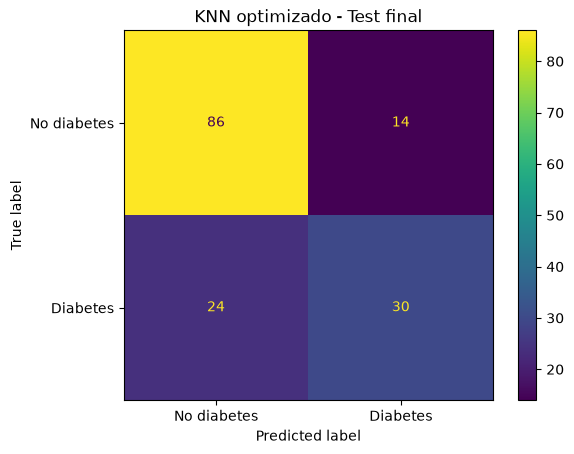

In [87]:
cm_knn_final = confusion_matrix(y_test, y_pred_knn_final)

print("=== MATRIZ DE CONFUSIÓN KNN ===")
print(cm_knn_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm_knn_final,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("KNN optimizado - Test final")
plt.show()

In [88]:
param_grid_mlp = {
    "model__hidden_layer_sizes": [
        (32,),
        (64,),
        (32, 16),
        (64, 32),
        (128, 64)
    ],
    "model__alpha": [0.0001, 0.001, 0.01],
    "model__learning_rate_init": [0.001, 0.01],
    "model__activation": ["relu", "tanh"]
}

grid_mlp = GridSearchCV(
    estimator=mlp_model,
    param_grid=param_grid_mlp,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

print("GridSearch de MLP configurado.")

GridSearch de MLP configurado.


In [89]:
print("=== OPTIMIZANDO MLP ===")

grid_mlp.fit(X_train, y_train)

print("Optimización de MLP finalizada.")

=== OPTIMIZANDO MLP ===
Optimización de MLP finalizada.


In [90]:
print("=== MEJORES PARÁMETROS MLP ===")
print(grid_mlp.best_params_)

print("\n=== MEJOR ROC-AUC EN VALIDACIÓN ===")
print(round(grid_mlp.best_score_, 4))

=== MEJORES PARÁMETROS MLP ===
{'model__activation': 'relu', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (32, 16), 'model__learning_rate_init': 0.01}

=== MEJOR ROC-AUC EN VALIDACIÓN ===
0.8507


In [91]:
best_mlp = grid_mlp.best_estimator_

print("Mejor MLP obtenido correctamente.")

Mejor MLP obtenido correctamente.


In [92]:
y_pred_mlp_final = best_mlp.predict(X_test)
y_prob_mlp_final = best_mlp.predict_proba(X_test)[:, 1]

print("=== MLP OPTIMIZADO — TEST FINAL ===")

print(f"Accuracy : {accuracy_score(y_test, y_pred_mlp_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_mlp_final):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_mlp_final):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_mlp_final):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob_mlp_final):.4f}")

=== MLP OPTIMIZADO — TEST FINAL ===
Accuracy : 0.7403
Precision: 0.6522
Recall   : 0.5556
F1-score : 0.6000
ROC-AUC  : 0.8161


=== MATRIZ DE CONFUSIÓN MLP ===
[[84 16]
 [24 30]]


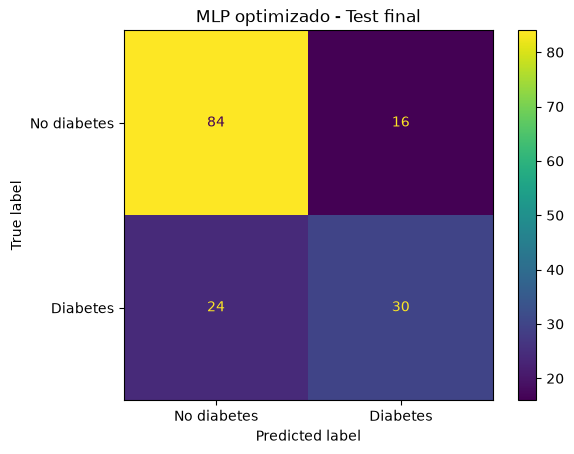

In [93]:
cm_mlp_final = confusion_matrix(y_test, y_pred_mlp_final)

print("=== MATRIZ DE CONFUSIÓN MLP ===")
print(cm_mlp_final)

ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp_final,
    display_labels=["No diabetes", "Diabetes"]
).plot()

plt.title("MLP optimizado - Test final")
plt.show()

In [94]:
resultados_finales = pd.DataFrame([
    {
        "Modelo": "Regresión Logística",
        "Accuracy": accuracy_score(y_test, y_pred_lr_final),
        "Precision": precision_score(y_test, y_pred_lr_final),
        "Recall": recall_score(y_test, y_pred_lr_final),
        "F1": f1_score(y_test, y_pred_lr_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_lr_final)
    },
    {
        "Modelo": "SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm_final),
        "Precision": precision_score(y_test, y_pred_svm_final),
        "Recall": recall_score(y_test, y_pred_svm_final),
        "F1": f1_score(y_test, y_pred_svm_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_svm_final)
    },
    {
        "Modelo": "KNN",
        "Accuracy": accuracy_score(y_test, y_pred_knn_final),
        "Precision": precision_score(y_test, y_pred_knn_final),
        "Recall": recall_score(y_test, y_pred_knn_final),
        "F1": f1_score(y_test, y_pred_knn_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_knn_final)
    },
    {
        "Modelo": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf_final),
        "Precision": precision_score(y_test, y_pred_rf_final),
        "Recall": recall_score(y_test, y_pred_rf_final),
        "F1": f1_score(y_test, y_pred_rf_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_rf_final)
    },
    {
        "Modelo": "MLP",
        "Accuracy": accuracy_score(y_test, y_pred_mlp_final),
        "Precision": precision_score(y_test, y_pred_mlp_final),
        "Recall": recall_score(y_test, y_pred_mlp_final),
        "F1": f1_score(y_test, y_pred_mlp_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_mlp_final)
    }
])

print("=== COMPARACIÓN FINAL EN TEST ===")
display(resultados_finales.round(4))

=== COMPARACIÓN FINAL EN TEST ===


,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Regresión Logística,0.6883,0.5652,0.4815,0.5200,0.8104
1,SVM,0.7078,0.6098,0.4630,0.5263,0.8052
2,KNN,0.7532,0.6818,0.5556,0.6122,0.8124
3,Random Forest,0.7273,0.6429,0.5000,0.5625,0.8043
4,MLP,0.7403,0.6522,0.5556,0.6000,0.8161


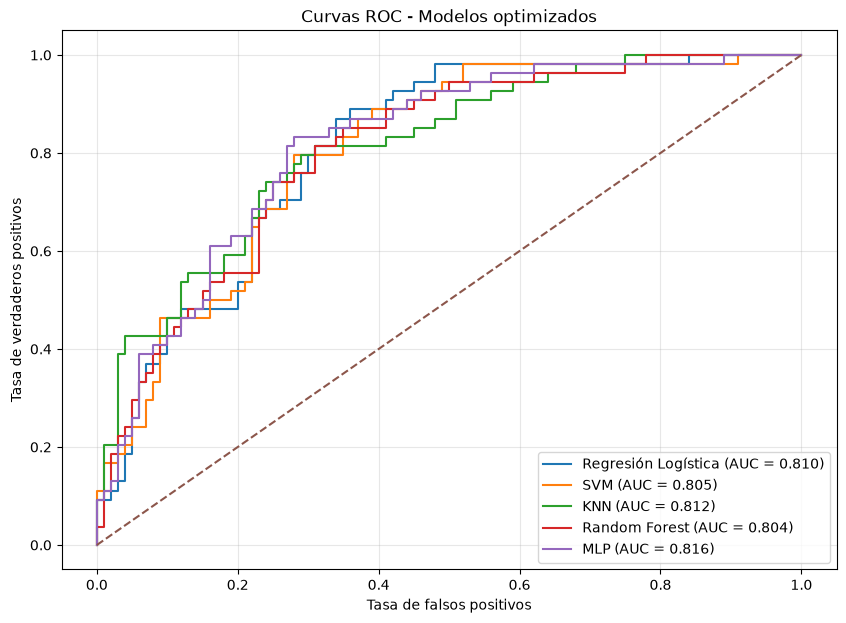

In [95]:
from sklearn.metrics import roc_curve

modelos_test = {
    "Regresión Logística": y_prob_lr_final,
    "SVM": y_prob_svm_final,
    "KNN": y_prob_knn_final,
    "Random Forest": y_prob_rf_final,
    "MLP": y_prob_mlp_final
}

plt.figure(figsize=(10, 7))

for nombre, probabilidades in modelos_test.items():
    fpr, tpr, _ = roc_curve(y_test, probabilidades)
    auc = roc_auc_score(y_test, probabilidades)

    plt.plot(
        fpr,
        tpr,
        label=f"{nombre} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC - Modelos optimizados")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [96]:
from sklearn.model_selection import train_test_split

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("=== DIVISIÓN PARA ANÁLISIS DE UMBRAL ===")
print(f"Subtrain: {X_subtrain.shape}")
print(f"Validación: {X_val.shape}")

=== DIVISIÓN PARA ANÁLISIS DE UMBRAL ===
Subtrain: (491, 8)
Validación: (123, 8)


In [97]:
from sklearn.base import clone

modelos_optimizados = {
    "Regresión Logística": grid_lr_corrected.best_estimator_,
    "SVM": grid_svm.best_estimator_,
    "KNN": grid_knn.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
    "MLP": grid_mlp.best_estimator_
}

In [98]:
from sklearn.base import clone

modelos_optimizados = {
    "Regresión Logística": grid_lr_corrected.best_estimator_,
    "SVM": grid_svm.best_estimator_,
    "KNN": grid_knn.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
    "MLP": grid_mlp.best_estimator_
}

In [99]:
modelos_validacion = {}

for nombre, modelo in modelos_optimizados.items():

    modelo_copia = clone(modelo)

    modelo_copia.fit(X_subtrain, y_subtrain)

    modelos_validacion[nombre] = modelo_copia

print("Modelos entrenados sobre Subtrain.")

c:\Users\alain\.vscode\DIABETES_AI\venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Modelos entrenados sobre Subtrain.


In [100]:
probabilidades_val = {}

for nombre, modelo in modelos_validacion.items():

    probabilidades_val[nombre] = modelo.predict_proba(X_val)[:, 1]

print("Probabilidades de validación calculadas.")

Probabilidades de validación calculadas.


In [101]:
from sklearn.metrics import precision_score, recall_score, f1_score

umbrales = np.arange(0.30, 0.71, 0.05)

resultados_umbral = []

for nombre, probabilidades in probabilidades_val.items():

    for umbral in umbrales:

        predicciones = (probabilidades >= umbral).astype(int)

        resultados_umbral.append({
            "Modelo": nombre,
            "Umbral": umbral,
            "Precision": precision_score(
                y_val,
                predicciones,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val,
                predicciones,
                zero_division=0
            ),
            "F1": f1_score(
                y_val,
                predicciones,
                zero_division=0
            )
        })

umbral_df = pd.DataFrame(resultados_umbral)

display(umbral_df.round(4))

,Modelo,Umbral,Precision,Recall,F1
0,Regresión Logística,0.30,0.6000,0.8372,0.6990
1,Regresión Logística,0.35,0.6400,0.7442,0.6882
2,Regresión Logística,0.40,0.7045,0.7209,0.7126
3,Regresión Logística,0.45,0.7436,0.6744,0.7073
4,Regresión Logística,0.50,0.7941,0.6279,0.7013
5,Regresión Logística,0.55,0.8387,0.6047,0.7027
6,Regresión Logística,0.60,0.8462,0.5116,0.6377
7,Regresión Logística,0.65,0.8400,0.4884,0.6176
8,Regresión Logística,0.70,0.8947,0.3953,0.5484
9,SVM,0.30,0.6429,0.8372,0.7273


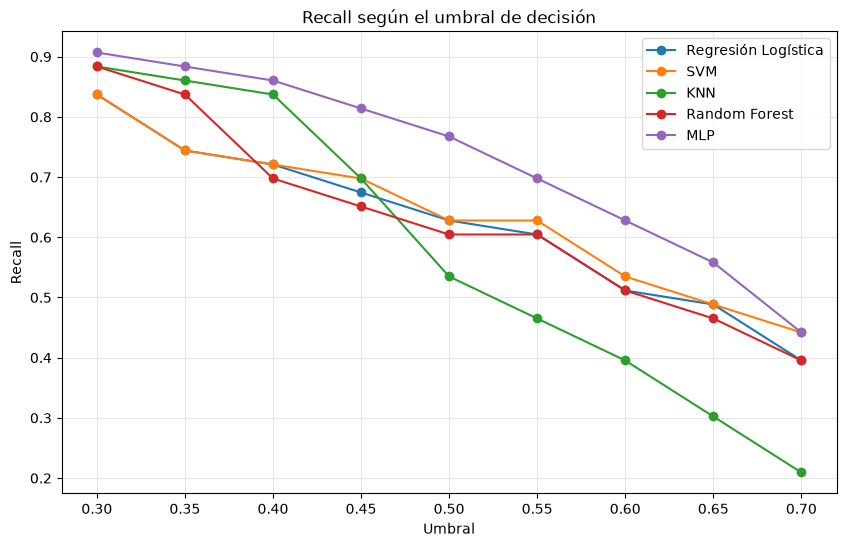

In [102]:
plt.figure(figsize=(10, 6))

for nombre in umbral_df["Modelo"].unique():

    datos = umbral_df[
        umbral_df["Modelo"] == nombre
    ]

    plt.plot(
        datos["Umbral"],
        datos["Recall"],
        marker="o",
        label=nombre
    )

plt.xlabel("Umbral")
plt.ylabel("Recall")
plt.title("Recall según el umbral de decisión")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

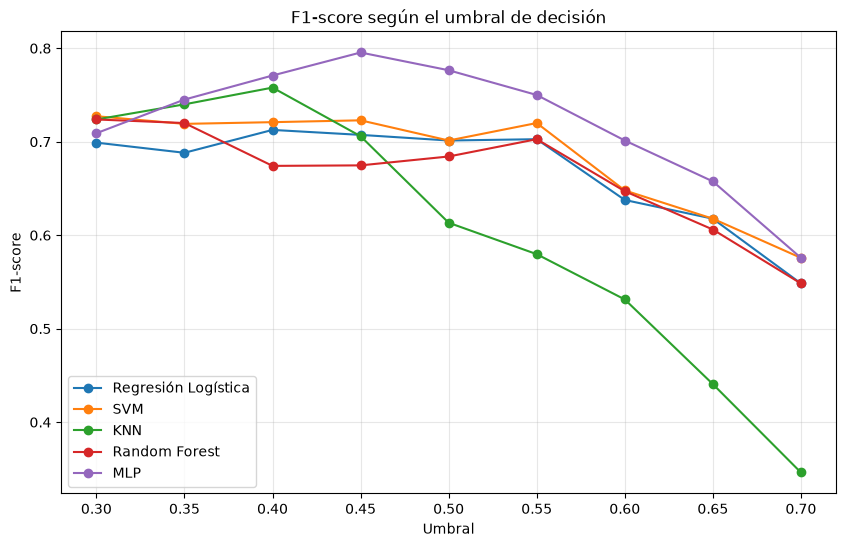

In [103]:
plt.figure(figsize=(10, 6))

for nombre in umbral_df["Modelo"].unique():

    datos = umbral_df[
        umbral_df["Modelo"] == nombre
    ]

    plt.plot(
        datos["Umbral"],
        datos["F1"],
        marker="o",
        label=nombre
    )

plt.xlabel("Umbral")
plt.ylabel("F1-score")
plt.title("F1-score según el umbral de decisión")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [104]:
print("=== MEJOR UMBRAL SEGÚN F1 ===")

mejores_umbrales = (
    umbral_df
    .sort_values(["Modelo", "F1"], ascending=[True, False])
    .groupby("Modelo")
    .head(1)
)

display(
    mejores_umbrales[
        ["Modelo", "Umbral", "Precision", "Recall", "F1"]
    ].round(4)
)

=== MEJOR UMBRAL SEGÚN F1 ===


,Modelo,Umbral,Precision,Recall,F1
20,KNN,0.40,0.6923,0.8372,0.7579
39,MLP,0.45,0.7778,0.8140,0.7955
27,Random Forest,0.30,0.6129,0.8837,0.7238
2,Regresión Logística,0.40,0.7045,0.7209,0.7126
9,SVM,0.30,0.6429,0.8372,0.7273


In [105]:
print("=== UMBRALES CON RECALL >= 0.60 ===")

recall_60 = umbral_df[
    umbral_df["Recall"] >= 0.60
].copy()

display(
    recall_60[
        ["Modelo", "Umbral", "Precision", "Recall", "F1"]
    ].sort_values(
        ["Modelo", "F1"],
        ascending=[True, False]
    ).round(4)
)

=== UMBRALES CON RECALL >= 0.60 ===


,Modelo,Umbral,Precision,Recall,F1
20,KNN,0.40,0.6923,0.8372,0.7579
19,KNN,0.35,0.6491,0.8605,0.7400
18,KNN,0.30,0.6129,0.8837,0.7238
21,KNN,0.45,0.7143,0.6977,0.7059
39,MLP,0.45,0.7778,0.8140,0.7955
40,MLP,0.50,0.7857,0.7674,0.7765
38,MLP,0.40,0.6981,0.8605,0.7708
41,MLP,0.55,0.8108,0.6977,0.7500
37,MLP,0.35,0.6441,0.8837,0.7451
36,MLP,0.30,0.5821,0.9070,0.7091


In [106]:
from sklearn.calibration import calibration_curve

In [107]:
prob_true_mlp, prob_pred_mlp = calibration_curve(
    y_val,
    probabilidades_val["MLP"],
    n_bins=10,
    strategy="uniform"
)

print("=== CALIBRACIÓN MLP ===")

for pred, real in zip(prob_pred_mlp, prob_true_mlp):
    print(
        f"Probabilidad predicha: {pred:.3f} | "
        f"Frecuencia observada: {real:.3f}"
    )

=== CALIBRACIÓN MLP ===
Probabilidad predicha: 0.037 | Frecuencia observada: 0.027
Probabilidad predicha: 0.155 | Frecuencia observada: 0.100
Probabilidad predicha: 0.250 | Frecuencia observada: 0.222
Probabilidad predicha: 0.348 | Frecuencia observada: 0.143
Probabilidad predicha: 0.441 | Frecuencia observada: 0.364
Probabilidad predicha: 0.541 | Frecuencia observada: 0.750
Probabilidad predicha: 0.665 | Frecuencia observada: 0.727
Probabilidad predicha: 0.750 | Frecuencia observada: 0.875
Probabilidad predicha: 0.830 | Frecuencia observada: 0.833
Probabilidad predicha: 0.926 | Frecuencia observada: 0.667


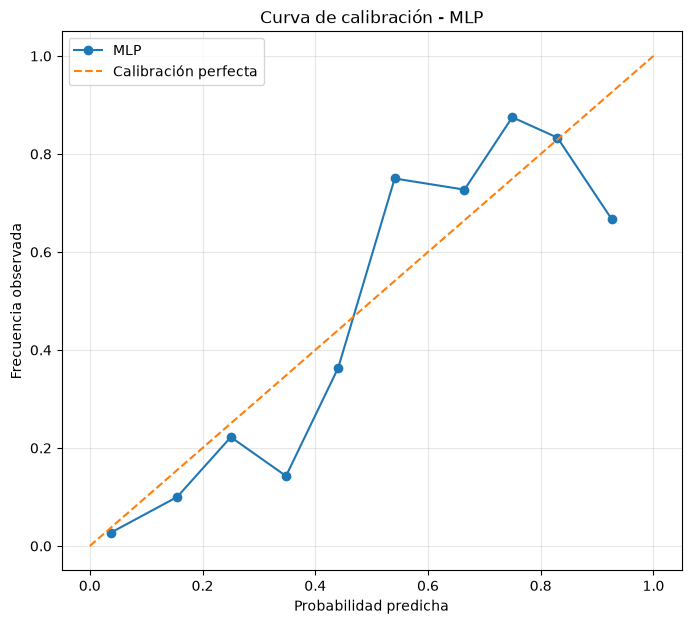

In [108]:
plt.figure(figsize=(8, 7))

plt.plot(
    prob_pred_mlp,
    prob_true_mlp,
    marker="o",
    label="MLP"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibración perfecta"
)

plt.xlabel("Probabilidad predicha")
plt.ylabel("Frecuencia observada")
plt.title("Curva de calibración - MLP")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [109]:
from sklearn.metrics import brier_score_loss

brier_mlp = brier_score_loss(
    y_val,
    probabilidades_val["MLP"]
)

print("=== BRIER SCORE MLP ===")
print(f"Brier Score: {brier_mlp:.4f}")

=== BRIER SCORE MLP ===
Brier Score: 0.1279


In [110]:
print("=== BRIER SCORE - TODOS LOS MODELOS ===")

brier_results = []

for nombre, probabilidades in probabilidades_val.items():

    score = brier_score_loss(
        y_val,
        probabilidades
    )

    brier_results.append({
        "Modelo": nombre,
        "Brier_Score": score
    })

brier_df = pd.DataFrame(brier_results)

display(
    brier_df.sort_values("Brier_Score").round(4)
)

=== BRIER SCORE - TODOS LOS MODELOS ===


,Modelo,Brier_Score
4,MLP,0.1279
1,SVM,0.1339
0,Regresión Logística,0.1374
3,Random Forest,0.1387
2,KNN,0.1407


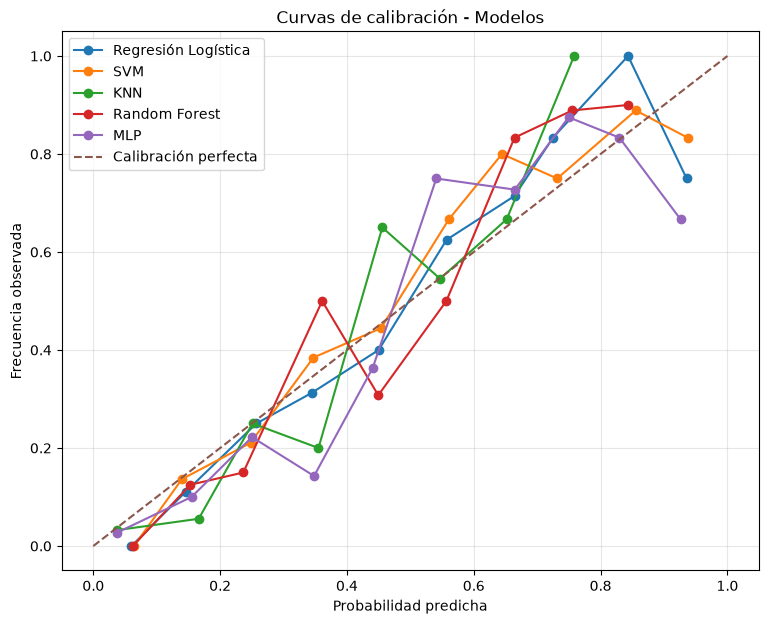

In [111]:
plt.figure(figsize=(9, 7))

for nombre, probabilidades in probabilidades_val.items():

    prob_true, prob_pred = calibration_curve(
        y_val,
        probabilidades,
        n_bins=10,
        strategy="uniform"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=nombre
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibración perfecta"
)

plt.xlabel("Probabilidad predicha")
plt.ylabel("Frecuencia observada")
plt.title("Curvas de calibración - Modelos")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [112]:
from sklearn.calibration import CalibratedClassifierCV

In [113]:
mlp_calibrated = CalibratedClassifierCV(
    estimator=grid_mlp.best_estimator_,
    method="sigmoid",
    cv=5
)

print("Modelo MLP calibrado configurado.")

Modelo MLP calibrado configurado.


In [114]:
print("=== CALIBRANDO MLP ===")

mlp_calibrated.fit(X_train, y_train)

print("Calibración finalizada.")

=== CALIBRANDO MLP ===
Calibración finalizada.


In [115]:
y_prob_mlp_cal = mlp_calibrated.predict_proba(X_test)[:, 1]

y_pred_mlp_cal = (
    y_prob_mlp_cal >= 0.50
).astype(int)

In [116]:
print("=== MLP CALIBRADO — TEST ===")

print(
    f"Accuracy : "
    f"{accuracy_score(y_test, y_pred_mlp_cal):.4f}"
)

print(
    f"Precision: "
    f"{precision_score(y_test, y_pred_mlp_cal):.4f}"
)

print(
    f"Recall   : "
    f"{recall_score(y_test, y_pred_mlp_cal):.4f}"
)

print(
    f"F1-score : "
    f"{f1_score(y_test, y_pred_mlp_cal):.4f}"
)

print(
    f"ROC-AUC  : "
    f"{roc_auc_score(y_test, y_prob_mlp_cal):.4f}"
)

print(
    f"Brier    : "
    f"{brier_score_loss(y_test, y_prob_mlp_cal):.4f}"
)

=== MLP CALIBRADO — TEST ===
Accuracy : 0.7273
Precision: 0.6154
Recall   : 0.5926
F1-score : 0.6038
ROC-AUC  : 0.8015
Brier    : 0.1749


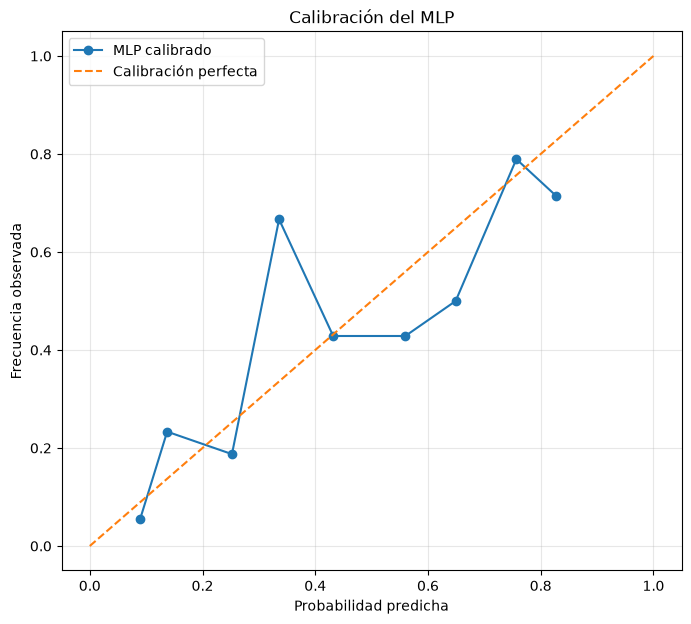

In [117]:
prob_true_cal, prob_pred_cal = calibration_curve(
    y_test,
    y_prob_mlp_cal,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(8, 7))

plt.plot(
    prob_pred_cal,
    prob_true_cal,
    marker="o",
    label="MLP calibrado"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibración perfecta"
)

plt.xlabel("Probabilidad predicha")
plt.ylabel("Frecuencia observada")
plt.title("Calibración del MLP")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [118]:
print("=== COMPARACIÓN MLP ANTES VS DESPUÉS DE CALIBRACIÓN ===")

brier_antes = brier_score_loss(
    y_test,
    y_prob_mlp_final
)

brier_despues = brier_score_loss(
    y_test,
    y_prob_mlp_cal
)

roc_antes = roc_auc_score(
    y_test,
    y_prob_mlp_final
)

roc_despues = roc_auc_score(
    y_test,
    y_prob_mlp_cal
)

print(f"Brier antes : {brier_antes:.4f}")
print(f"Brier después: {brier_despues:.4f}")

print(f"\nROC-AUC antes : {roc_antes:.4f}")
print(f"ROC-AUC después: {roc_despues:.4f}")

=== COMPARACIÓN MLP ANTES VS DESPUÉS DE CALIBRACIÓN ===
Brier antes : 0.1700
Brier después: 0.1749

ROC-AUC antes : 0.8161
ROC-AUC después: 0.8015


In [119]:
from sklearn.inspection import permutation_importance

In [120]:
print("=== IMPORTANCIA DE VARIABLES — MLP ===")

perm_mlp = permutation_importance(
    modelos_validacion["MLP"],
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

=== IMPORTANCIA DE VARIABLES — MLP ===


In [121]:
importancia_mlp = pd.DataFrame({
    "Variable": X_val.columns,
    "Importancia_media": perm_mlp.importances_mean,
    "Importancia_std": perm_mlp.importances_std
})

importancia_mlp = importancia_mlp.sort_values(
    "Importancia_media",
    ascending=False
)

display(importancia_mlp.round(4))

,Variable,Importancia_media,Importancia_std
1,Glucose,0.1498,0.0275
0,Pregnancies,0.0300,0.0101
5,BMI,0.0161,0.0103
4,Insulin,0.0095,0.0093
2,BloodPressure,0.0077,0.0060
6,DiabetesPedigreeFunction,0.0057,0.0102
3,SkinThickness,0.0020,0.0058
7,Age,0.0008,0.0051


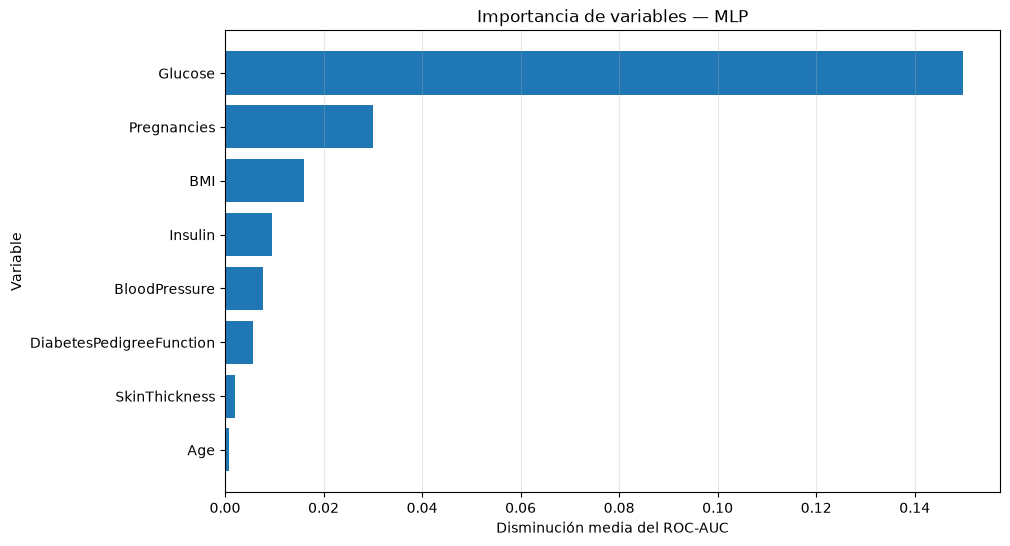

In [122]:
plt.figure(figsize=(10, 6))

plt.barh(
    importancia_mlp["Variable"],
    importancia_mlp["Importancia_media"]
)

plt.xlabel("Disminución media del ROC-AUC")
plt.ylabel("Variable")
plt.title("Importancia de variables — MLP")
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.show()

In [123]:
import shap

print("SHAP instalado correctamente.")
print(f"Versión: {shap.__version__}")

SHAP instalado correctamente.
Versión: 0.52.0


In [124]:
print(best_mlp)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(32, 16),
                               learning_rate_init=0.01, max_iter=1000,
                               random_state=42))])


In [125]:
print(best_mlp.named_steps)

{'imputer': SimpleImputer(strategy='median'), 'scaler': StandardScaler(), 'model': MLPClassifier(alpha=0.001, early_stopping=True, hidden_layer_sizes=(32, 16),
              learning_rate_init=0.01, max_iter=1000, random_state=42)}


In [126]:
import shap

print("Versión de SHAP:", shap.__version__)

Versión de SHAP: 0.52.0


In [127]:
def predict_proba_shap(X):
    return best_mlp.predict_proba(X)[:, 1]

In [128]:
X_background = X_subtrain.sample(
    n=min(100, len(X_subtrain)),
    random_state=42
)

X_explain = X_val.sample(
    n=min(100, len(X_val)),
    random_state=42
)

print("Background:", X_background.shape)
print("Datos a explicar:", X_explain.shape)

Background: (100, 8)
Datos a explicar: (100, 8)


In [129]:
explainer = shap.Explainer(
    predict_proba_shap,
    X_background,
    algorithm="permutation"
)

shap_values = explainer(
    X_explain
)

print("SHAP calculado correctamente.")

PermutationExplainer explainer: 101it [00:48,  2.06it/s]                         

SHAP calculado correctamente.


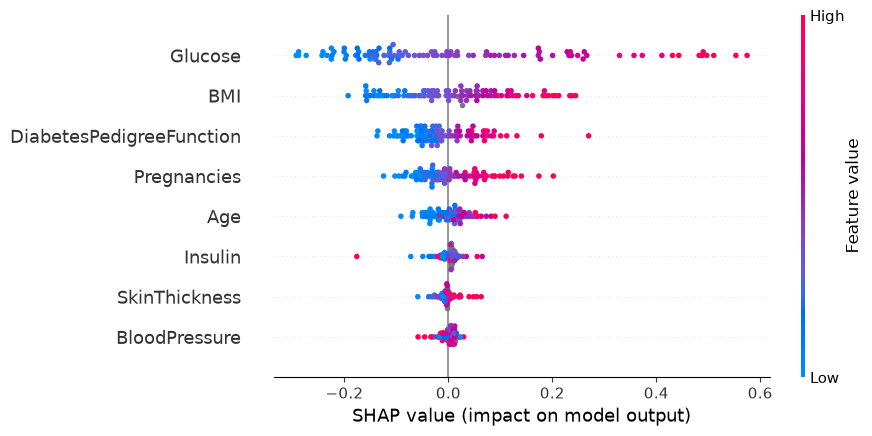

In [130]:
shap.plots.beeswarm(
    shap_values,
    max_display=8
)

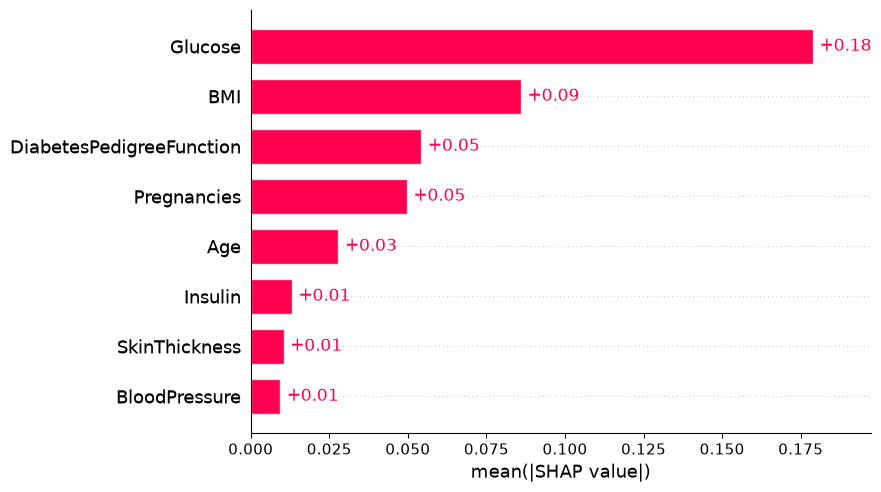

In [131]:
shap.plots.bar(
    shap_values,
    max_display=8
)

In [132]:
paciente_idx = X_explain.index[0]

paciente = X_explain.loc[[paciente_idx]]

print("=== PACIENTE SELECCIONADO ===")
display(paciente)

=== PACIENTE SELECCIONADO ===


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
617,2,68.0,62.0,13.0,15.0,20.1,0.257,23


In [133]:
probabilidad = best_mlp.predict_proba(paciente)[0, 1]
prediccion = int(probabilidad >= 0.50)

print("=== PREDICCIÓN INDIVIDUAL ===")
print(f"Probabilidad estimada: {probabilidad:.4f}")
print(f"Porcentaje estimado: {probabilidad * 100:.2f}%")
print(f"Clase predicha: {prediccion}")

=== PREDICCIÓN INDIVIDUAL ===
Probabilidad estimada: 0.0004
Porcentaje estimado: 0.04%
Clase predicha: 0


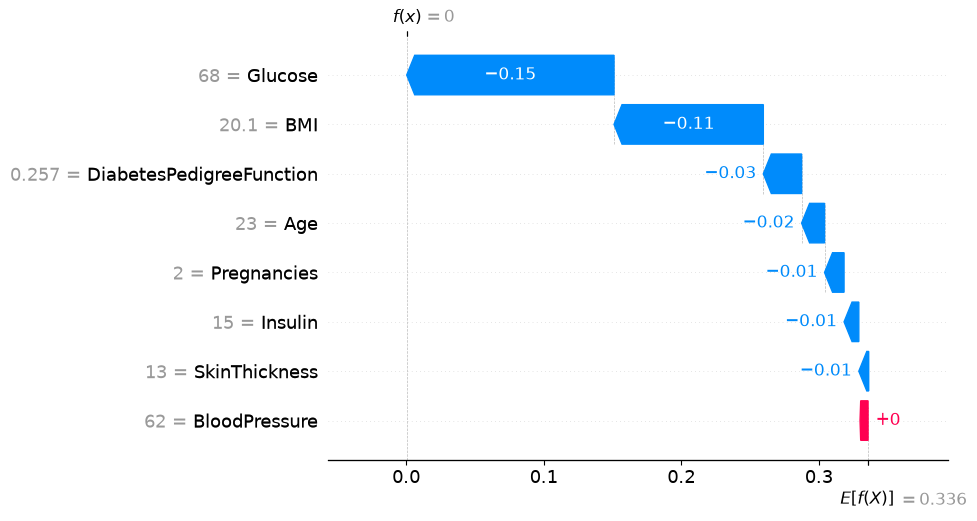

In [134]:
posicion = list(X_explain.index).index(paciente_idx)

shap.plots.waterfall(
    shap_values[posicion],
    max_display=8
)

In [135]:
print("=== RESULTADOS FINALES — TEST INDEPENDIENTE ===")

resultados_finales = pd.DataFrame([
    {
        "Modelo": "Regresión Logística",
        "Accuracy": accuracy_score(y_test, y_pred_lr_final),
        "Precision": precision_score(y_test, y_pred_lr_final),
        "Recall": recall_score(y_test, y_pred_lr_final),
        "F1": f1_score(y_test, y_pred_lr_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_lr_final)
    },
    {
        "Modelo": "SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm_final),
        "Precision": precision_score(y_test, y_pred_svm_final),
        "Recall": recall_score(y_test, y_pred_svm_final),
        "F1": f1_score(y_test, y_pred_svm_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_svm_final)
    },
    {
        "Modelo": "KNN",
        "Accuracy": accuracy_score(y_test, y_pred_knn_final),
        "Precision": precision_score(y_test, y_pred_knn_final),
        "Recall": recall_score(y_test, y_pred_knn_final),
        "F1": f1_score(y_test, y_pred_knn_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_knn_final)
    },
    {
        "Modelo": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf_final),
        "Precision": precision_score(y_test, y_pred_rf_final),
        "Recall": recall_score(y_test, y_pred_rf_final),
        "F1": f1_score(y_test, y_pred_rf_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_rf_final)
    },
    {
        "Modelo": "MLP",
        "Accuracy": accuracy_score(y_test, y_pred_mlp_final),
        "Precision": precision_score(y_test, y_pred_mlp_final),
        "Recall": recall_score(y_test, y_pred_mlp_final),
        "F1": f1_score(y_test, y_pred_mlp_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_mlp_final)
    }
])

display(resultados_finales.round(4))

=== RESULTADOS FINALES — TEST INDEPENDIENTE ===


,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Regresión Logística,0.6883,0.5652,0.4815,0.5200,0.8104
1,SVM,0.7078,0.6098,0.4630,0.5263,0.8052
2,KNN,0.7532,0.6818,0.5556,0.6122,0.8124
3,Random Forest,0.7273,0.6429,0.5000,0.5625,0.8043
4,MLP,0.7403,0.6522,0.5556,0.6000,0.8161


In [136]:
print("=== RESULTADOS FINALES — TEST INDEPENDIENTE ===")

resultados_finales = pd.DataFrame([
    {
        "Modelo": "Regresión Logística",
        "Accuracy": accuracy_score(y_test, y_pred_lr_final),
        "Precision": precision_score(y_test, y_pred_lr_final),
        "Recall": recall_score(y_test, y_pred_lr_final),
        "F1": f1_score(y_test, y_pred_lr_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_lr_final)
    },
    {
        "Modelo": "SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm_final),
        "Precision": precision_score(y_test, y_pred_svm_final),
        "Recall": recall_score(y_test, y_pred_svm_final),
        "F1": f1_score(y_test, y_pred_svm_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_svm_final)
    },
    {
        "Modelo": "KNN",
        "Accuracy": accuracy_score(y_test, y_pred_knn_final),
        "Precision": precision_score(y_test, y_pred_knn_final),
        "Recall": recall_score(y_test, y_pred_knn_final),
        "F1": f1_score(y_test, y_pred_knn_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_knn_final)
    },
    {
        "Modelo": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf_final),
        "Precision": precision_score(y_test, y_pred_rf_final),
        "Recall": recall_score(y_test, y_pred_rf_final),
        "F1": f1_score(y_test, y_pred_rf_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_rf_final)
    },
    {
        "Modelo": "MLP",
        "Accuracy": accuracy_score(y_test, y_pred_mlp_final),
        "Precision": precision_score(y_test, y_pred_mlp_final),
        "Recall": recall_score(y_test, y_pred_mlp_final),
        "F1": f1_score(y_test, y_pred_mlp_final),
        "ROC_AUC": roc_auc_score(y_test, y_prob_mlp_final)
    }
])

display(resultados_finales.round(4))

=== RESULTADOS FINALES — TEST INDEPENDIENTE ===


,Modelo,Accuracy,Precision,Recall,F1,ROC_AUC
0,Regresión Logística,0.6883,0.5652,0.4815,0.5200,0.8104
1,SVM,0.7078,0.6098,0.4630,0.5263,0.8052
2,KNN,0.7532,0.6818,0.5556,0.6122,0.8124
3,Random Forest,0.7273,0.6429,0.5000,0.5625,0.8043
4,MLP,0.7403,0.6522,0.5556,0.6000,0.8161


In [137]:
modelo_final = grid_mlp.best_estimator_

print(modelo_final)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(32, 16),
                               learning_rate_init=0.01, max_iter=1000,
                               random_state=42))])


In [138]:
features_modelo = X_train.columns.tolist()

print("=== VARIABLES DEL MODELO ===")

for i, variable in enumerate(features_modelo, start=1):
    print(f"{i}. {variable}")

=== VARIABLES DEL MODELO ===
1. Pregnancies
2. Glucose
3. BloodPressure
4. SkinThickness
5. Insulin
6. BMI
7. DiabetesPedigreeFunction
8. Age


In [139]:
import os

os.makedirs("../models", exist_ok=True)

print("Carpeta models preparada.")

Carpeta models preparada.


In [140]:
import joblib

In [141]:
ruta_modelo = "../models/mlp_diabetes_pipeline_v1.joblib"

joblib.dump(
    modelo_final,
    ruta_modelo
)

print("Modelo guardado correctamente.")
print(f"Ruta: {ruta_modelo}")

Modelo guardado correctamente.
Ruta: ../models/mlp_diabetes_pipeline_v1.joblib


In [142]:
modelo_cargado = joblib.load(ruta_modelo)

print("Modelo cargado correctamente.")
print(modelo_cargado)

Modelo cargado correctamente.
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(32, 16),
                               learning_rate_init=0.01, max_iter=1000,
                               random_state=42))])


In [143]:
prediccion_prueba = modelo_cargado.predict(X_test.iloc[[0]])
probabilidad_prueba = modelo_cargado.predict_proba(X_test.iloc[[0]])[0, 1]

print("=== PRUEBA DEL MODELO GUARDADO ===")
print(f"Predicción: {prediccion_prueba[0]}")
print(f"Probabilidad estimada: {probabilidad_prueba:.4f}")

=== PRUEBA DEL MODELO GUARDADO ===
Predicción: 1
Probabilidad estimada: 0.7314


In [144]:
import json
from datetime import datetime

metadata_modelo = {
    "model_name": "MLP Diabetes Prediction",
    "version": "1.0.0",
    "model_type": "MLPClassifier",
    "task": "binary_classification",
    "target": "Outcome",
    "features": features_modelo,
    "hyperparameters": grid_mlp.best_params_,
    "training_dataset": "Pima Indians Diabetes Database",
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "test_metrics": {
        "accuracy": round(accuracy_score(y_test, y_pred_mlp_final), 4),
        "precision": round(precision_score(y_test, y_pred_mlp_final), 4),
        "recall": round(recall_score(y_test, y_pred_mlp_final), 4),
        "f1": round(f1_score(y_test, y_pred_mlp_final), 4),
        "roc_auc": round(roc_auc_score(y_test, y_prob_mlp_final), 4),
        "brier_score": round(
            brier_score_loss(y_test, y_prob_mlp_final),
            4
        )
    },
    "validation_roc_auc": round(grid_mlp.best_score_, 4),
    "threshold_analysis": {
        "candidate_threshold": 0.45,
        "selection_metric": "F1",
        "selection_dataset": "validation"
    },
    "created_at": datetime.now().isoformat(),
    "status": "research_prototype"
}

ruta_metadata = "../models/mlp_diabetes_pipeline_v1_metadata.json"

with open(ruta_metadata, "w", encoding="utf-8") as f:
    json.dump(
        metadata_modelo,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Metadatos guardados correctamente.")
print(ruta_metadata)

Metadatos guardados correctamente.
../models/mlp_diabetes_pipeline_v1_metadata.json
